In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
import torchvision.transforms as T
import torchvision.models as models
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

In [48]:
df = pd.read_csv("Data_Entry_2017.csv")
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
 11  Unnamed: 11                  0 non-null       float64
dtypes: float64(3), int64(5), object(4)
memory usage: 10.3+ MB


,Follow-up #,Patient ID,Patient Age,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
count,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,0.0
mean,8.573751,14346.381743,46.901463,2646.078844,2486.438842,0.155649,0.155649,NaN
std,15.406320,8403.876972,16.839923,341.246429,401.268227,0.016174,0.016174,NaN
min,0.000000,1.000000,1.000000,1143.000000,966.000000,0.115000,0.115000,NaN
25%,0.000000,7310.750000,35.000000,2500.000000,2048.000000,0.143000,0.143000,NaN
50%,3.000000,13993.000000,49.000000,2518.000000,2544.000000,0.143000,0.143000,NaN
75%,10.000000,20673.000000,59.000000,2992.000000,2991.000000,0.168000,0.168000,NaN
max,183.000000,30805.000000,414.000000,3827.000000,4715.000000,0.198800,0.198800,NaN


In [49]:
df = df.drop(columns = ['Unnamed: 11'])

In [50]:
# patients with age greater than 100 are likely to be data entry errors

df = df[df['Patient Age'] <= 100]

<Axes: >

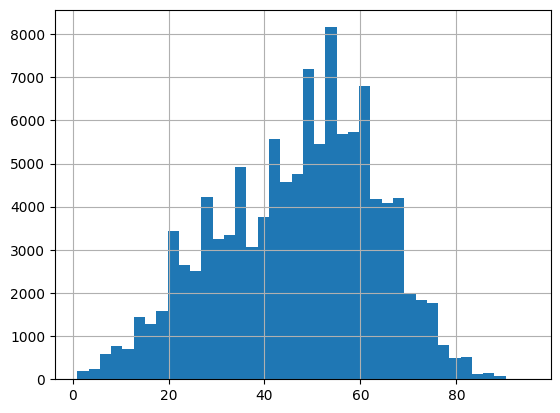

In [51]:
df['Patient Age'].hist(bins=40)

# Basic structure checks

In [52]:
# structure checks
n_images = len(df)
n_patients = df['Patient ID'].nunique()
gender_counts = df['Patient Gender'].value_counts()
view_position_counts = df['View Position'].value_counts()

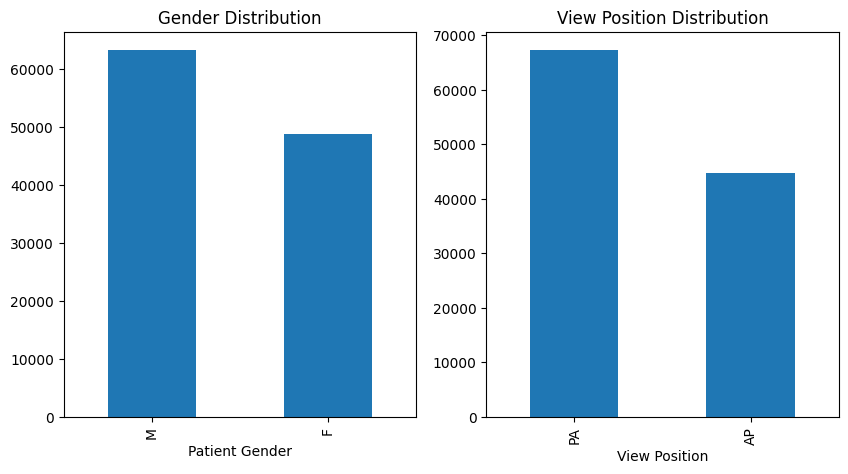

In [53]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
gender_counts.plot(kind='bar', title='Gender Distribution')
plt.subplot(1,2,2)
view_position_counts.plot(kind='bar', title='View Position Distribution')
plt.show()

Seems to be about 12k more male patients than females and majority of xrays were PA (posterioranterior)

# Image resolution/aspect ratio checks

<Axes: >

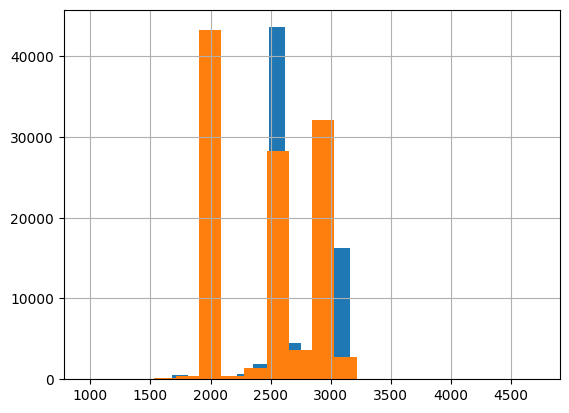

In [54]:
# width and height distributions
df['OriginalImage[Width'].hist(bins=20)
df['Height]'].hist(bins=20)

In [55]:
df[["OriginalImage[Width", "Height]"]].value_counts().head(20)

OriginalImage[Width  Height]
2500                 2048       37153
2992                 2991       21954
3056                 2544       15334
2048                 2500        8683
2021                 2021        4411
2544                 3056        2418
2990                 2991         483
2020                 2021         331
2021                 2020         279
2986                 2991         166
2992                 2989         140
2674                 2991          93
2982                 2991          90
2742                 2991          86
2892                 2948          86
2758                 2991          82
2666                 2991          82
2686                 2991          80
2650                 2991          79
2694                 2991          78
Name: count, dtype: int64

most images are 2500x2048 pixels, 2992x2991 pixels, or 3056x2544 pixels

<Axes: >

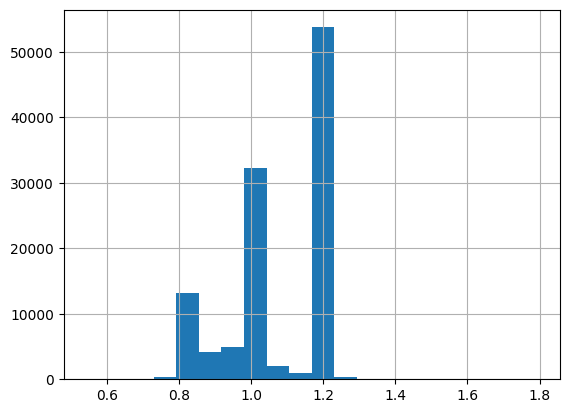

In [56]:
# aspect ratio
df['aspect_ratio'] = df['OriginalImage[Width'] / df['Height]']
df['aspect_ratio'].hist(bins=20)

1.0 = sqaure images, 0.8 and 1.2 are slightly less square-ish. but there are also some weird edge cases that might be cropped differently or rotated or something else so should look into those

In [57]:
# code to see how many 'weird' aspect ratios there are in the dataset
weird = df[(df["aspect_ratio"] < 0.8) | (df["aspect_ratio"] > 1.3)]
len(weird), len(weird) / len(df)

(547, 0.004879397702133733)

so out of 112k+, 547 are this weird edge case

In [58]:
# exploring the weird aspect ratios

weird[["Image Index",
       "OriginalImage[Width",
       "Height]",
       "View Position"]].head()

weird["View Position"].value_counts()
weird[["OriginalImage[Width", "Height]"]].drop_duplicates().sort_values(
    ["OriginalImage[Width", "Height]"]
).head(20)

,OriginalImage[Width,Height]
87995,1414,966
52103,1442,2074
52869,1484,2020
92293,1537,2021
107079,1540,2021
85716,1545,2021
106966,1549,2021
96447,1550,1167
101755,1551,2021
109251,1559,2021


this table shows patient id and the associated resolutions. gonna separate these out and and drop them from the rest of the dataset (these images are only ~0.5% of the dataset)

In [59]:
df['aspect_ratio'] = df['OriginalImage[Width'] / df['Height]']
mask_weird = (df['aspect_ratio'] < 0.8) | (df['aspect_ratio'] > 1.3)

print('Weird count:', mask_weird.sum())

df['is_weird_ratio'] = mask_weird.astype(int)

# clean dataframe
df_clean = df[~mask_weird].reset_index(drop=True)


Weird count: 547


# Follow up/patient dynamics

count    30674.000000
mean         3.636859
std          7.254456
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
Name: Image Index, dtype: float64

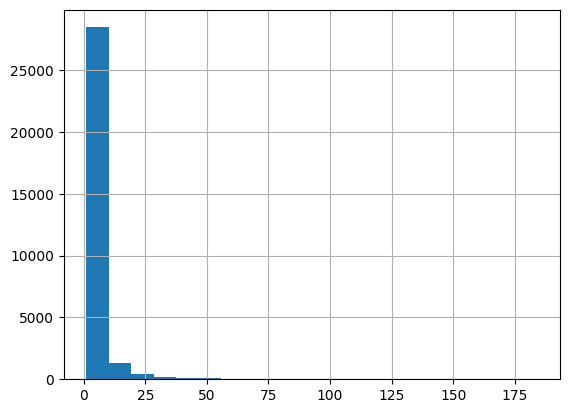

In [60]:
images_per_patient = df_clean.groupby('Patient ID')['Image Index'].count()
images_per_patient.hist(bins=20)
images_per_patient.describe()

there is a high chance the max value of 184 is a data entry error so will look morei nto it

In [61]:
images_per_patient.sort_values(ascending=False).head()

# grab that patient's images
top_patient_id = images_per_patient.idxmax()
df_clean[df_clean["Patient ID"] == top_patient_id]["Follow-up #"].describe()
df_clean[df_clean["Patient ID"] == top_patient_id]["Follow-up #"].sort_values().head()
df_clean[df_clean["Patient ID"] == top_patient_id]["Follow-up #"].sort_values().tail()

38165    179
38166    180
38167    181
38168    182
38169    183
Name: Follow-up #, dtype: int64

since there are multiple entries of image records, this means this patient's information is not an error and they did have 184 images/examinations taken

<Axes: >

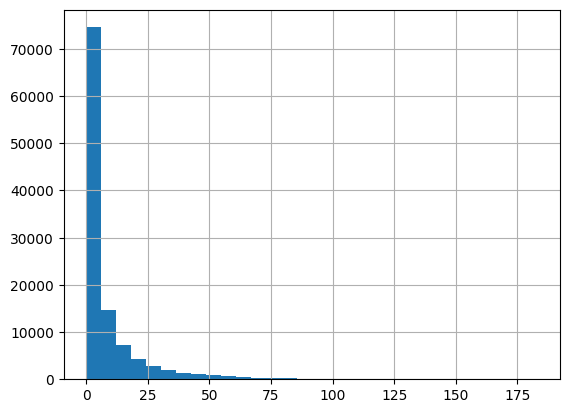

In [62]:
# checking follow up numbers

df_clean['Follow-up #'].hist(bins=30)

In [63]:
# calculating fractions of baseline and follow-up images, higher fraction means which type is more prevalent
baseline_frac = (df_clean["Follow-up #"] == 0).mean()
follow_frac   = (df_clean["Follow-up #"] > 0).mean()
baseline_frac, follow_frac

(np.float64(0.2741199566141076), np.float64(0.7258800433858924))

Each patient has one baseline exam and may have multiple follow up exams. Distribution is right skewed, where most exams have a low amount of follow-ups and a long tail all the way up to 183

# EDA and Visualization for the images

In [64]:
img_root = Path('NIH dataset images')

# grabbing all image paths and making sure they match the dataframe length
all_image_paths = list(img_root.rglob('*.png'))
len(all_image_paths)

112120

In [65]:
# map: '00000001_000.png' -> Path('NIH dataset images/images_001/images/00000001_000.png')
image_map = {p.name: p for p in all_image_paths}

# sanity checks for full coverage
filenames = set(df_clean['Image Index'])
missing_files = filenames - set(image_map.keys())
len(missing_files)

0

In [66]:
df_clean["img_path"] = df_clean["Image Index"].map(image_map)
df_clean["img_path"].isna().sum()

np.int64(0)

Sanity checks for visualization

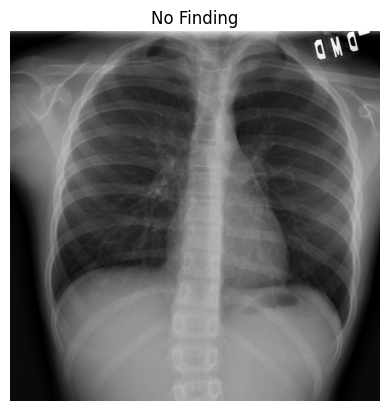

In [67]:
row = df_clean.sample(1, random_state = 0).iloc[0]
img = Image.open(row['img_path'])

plt.imshow(img, cmap='gray')
plt.title(row['Finding Labels'])
plt.axis('off')
plt.show()

right now data is written as something like 'Atlectasis|Effusion', 'Mass|Nodule', etc. cant filter for all Atlectasis or all Pneumonia, etc. therefore need to create multi hot columns where each string will have original string label and numeric representation. Ex:

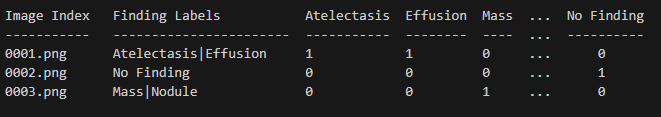


Image Index   Finding Labels           Atelectasis  Effusion  Mass  ...  No Finding

-----------   -----------------------  -----------  --------  ----  ...  ----------

0001.png      Atelectasis|Effusion     1            1         0     ...      0

0002.png      No Finding               0            0         0     ...      1

0003.png      Mass|Nodule              0            0         1     ...      0




In [ ]:
# extracting all unique labels from the 'Finding Labels' column
all_labels = sorted(
    set(
        label
        for s in df_clean['Finding Labels']
        for label in s.split('|')
    )
)

print("All labels:", all_labels)

# create multi-hot encoded columns for each label
for label in all_labels:
    df_clean[label] = df_clean['Finding Labels'].str.contains(label).astype(int)


# below is code for label counts per condition
label_counts = df_clean[all_labels].sum().sort_values(ascending=False)

print("Label counts (most common to least common):")
print(label_counts)

# optional: turn into a dataframe for cleaner display / saving
label_counts_df = (
    label_counts
    .reset_index()
    .rename(columns={"index": "Label", 0: "Count"})
)

display(label_counts_df)

# save counts if you want
label_counts_df.to_csv("label_counts_sorted.csv", index=False)

# top 5 labels by prevalence
top5 = label_counts.head(5).index.tolist()
print("\nTop 5 labels:", top5)

# optional: print counts for just the top 5
print("\nTop 5 label counts:")
for label in top5:
    print(f"{label}: {int(label_counts[label])}")

All labels: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
Label counts (most common to least common):
No Finding            60056
Infiltration          19793
Effusion              13267
Atelectasis           11521
Nodule                 6292
Mass                   5754
Pneumothorax           5262
Consolidation          4656
Pleural_Thickening     3369
Cardiomegaly           2763
Emphysema              2506
Edema                  2294
Fibrosis               1675
Pneumonia              1422
Hernia                  226
dtype: int64


,Label,Count
0,No Finding,60056
1,Infiltration,19793
2,Effusion,13267
3,Atelectasis,11521
4,Nodule,6292
5,Mass,5754
6,Pneumothorax,5262
7,Consolidation,4656
8,Pleural_Thickening,3369
9,Cardiomegaly,2763



Top 5 labels: ['No Finding', 'Infiltration', 'Effusion', 'Atelectasis', 'Nodule']

Top 5 label counts:
No Finding: 60056
Infiltration: 19793
Effusion: 13267
Atelectasis: 11521
Nodule: 6292


Random grid of images and labels

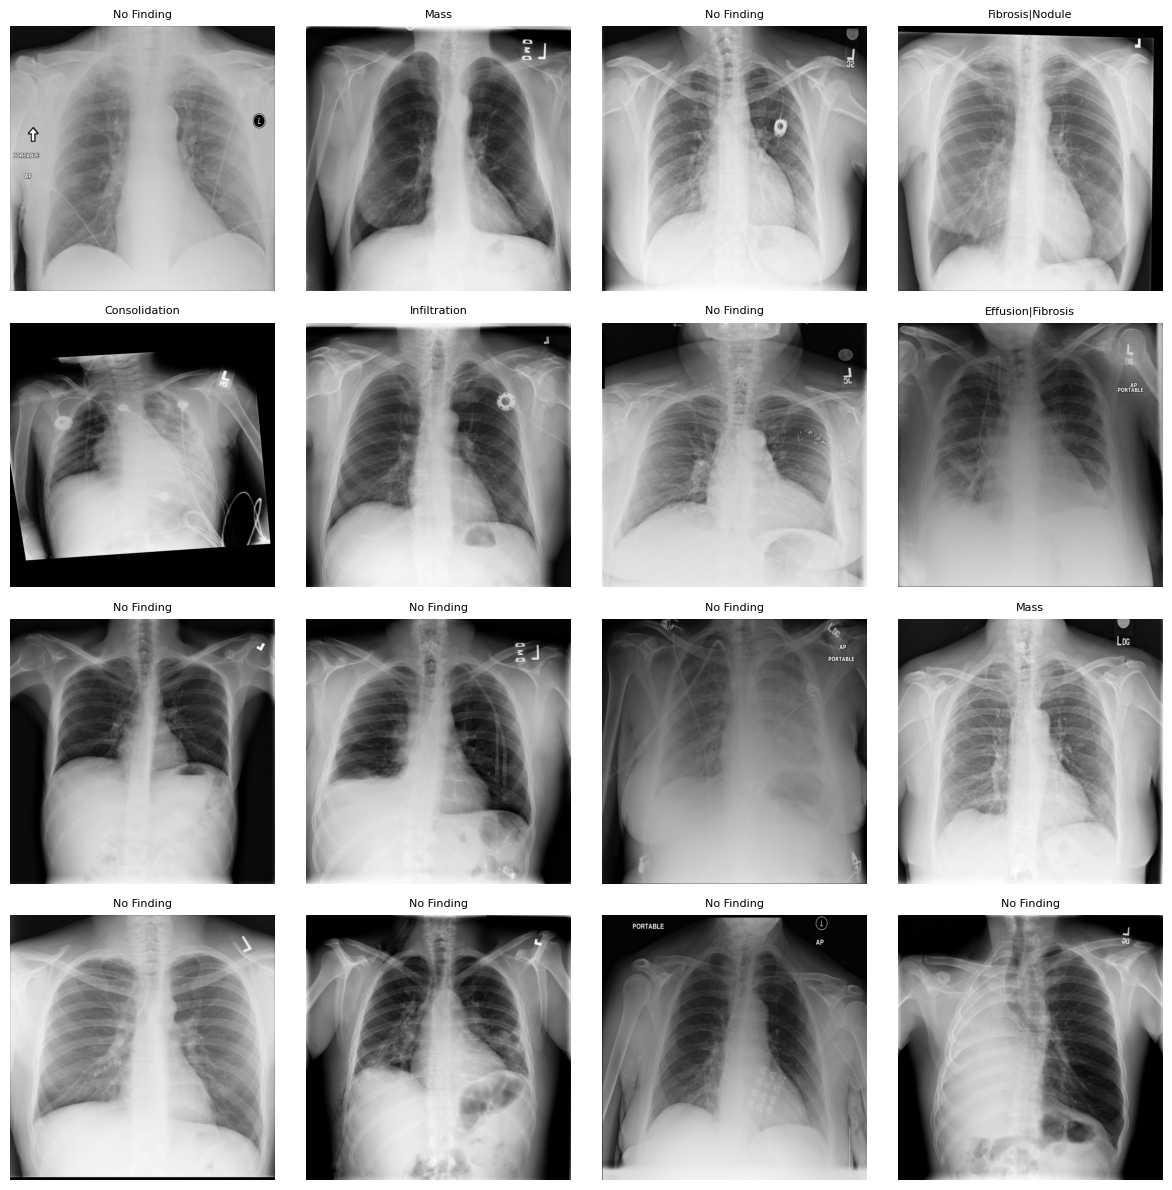

In [69]:
def show_random_grid(df, n = 16, seed = 0):
    '''
    Function to show a random grid of n images from the dataframe df.
    
    Parameters:
    n: number of images to show
    seed: random seed for reproducibility
    
    Returns:
    None, displays a grid of images
    '''    
    # sample n images
    sample = df_clean.sample(n, random_state=seed)
    cols = int(np.sqrt(n))
    rows = int(np.ceil(n / cols))
    
    # create subplots
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    axes = axes.ravel()
    
    # plot images
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = Image.open(row['img_path']).convert('L')
        ax.imshow(img, cmap='gray')
        ax.set_title(row['Finding Labels'], fontsize=8)
        ax.axis('off')
        
    # hide any extra axes if n is not a perfect square
    for ax in axes[len(sample):]:
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

show_random_grid(df_clean, n=16, seed=42)

some inconsistency in no finding xrays but no finding does not mean healthy. no finding means that the person can have a different disease that is not within the 14 categories in NIH dataset

looking at examples from each category

In [70]:
def show_examples_for_label(df, label, n = 9, seed = 31):
    '''
    Function to show n example images for a given label from the dataframe df.
    
    Parameters:
    df: dataframe containing image data
    label: label/condition to filter images
    n: number of images to show
    seed: random seed for reproducibility
    
    Returns:
    None, displays a grid of images
    '''
    
    # sample n images for the given label
    subset = df[df[label] == 1]
    sample = subset.sample(min(n, len(subset)), random_state=seed)
    
    # calculate number of rows and columns
    cols = 3
    rows = int(np.ceil(len(sample) / cols))
    
    # create subplots
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    axes = axes.ravel()
    
    # plot images
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = Image.open(row['img_path']).convert('L') # convert to grayscale
        ax.imshow(img, cmap='gray') 
        ax.set_title(f'{label}\n{row["Finding Labels"]}', fontsize=8) # title with label and findings
        ax.axis('off')
    
    # hide any extra axes if n is not a perfect square
    for ax in axes[len(sample):]:
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

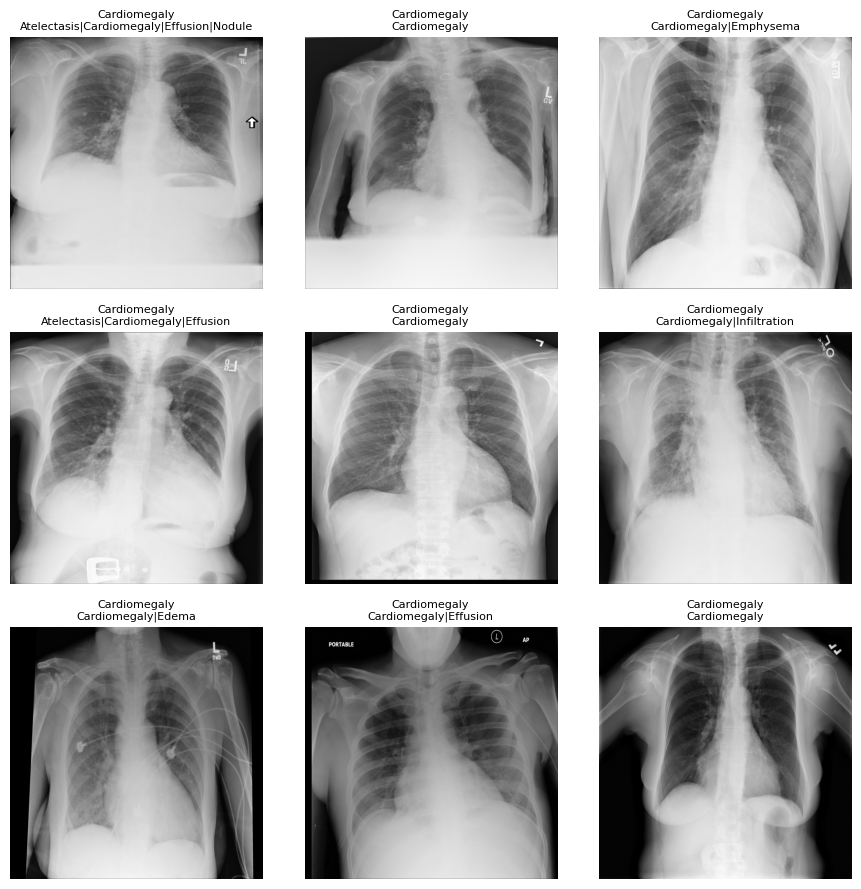

In [71]:
show_examples_for_label(df_clean, 'Cardiomegaly', n=9)

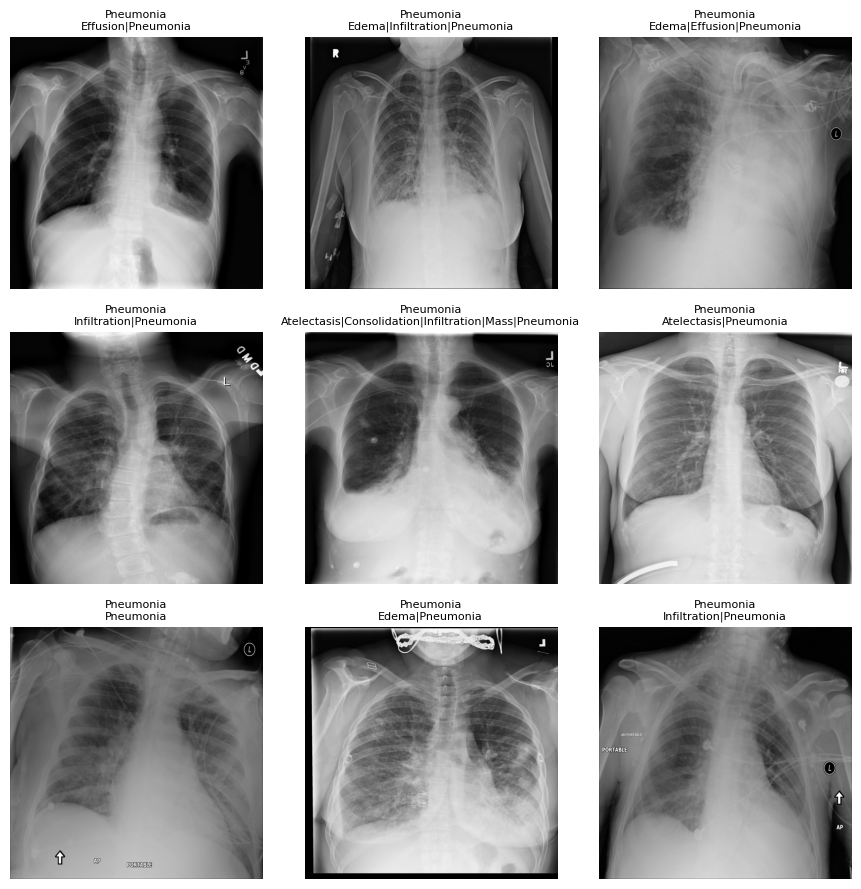

In [72]:
show_examples_for_label(df_clean, 'Pneumonia', n=9)

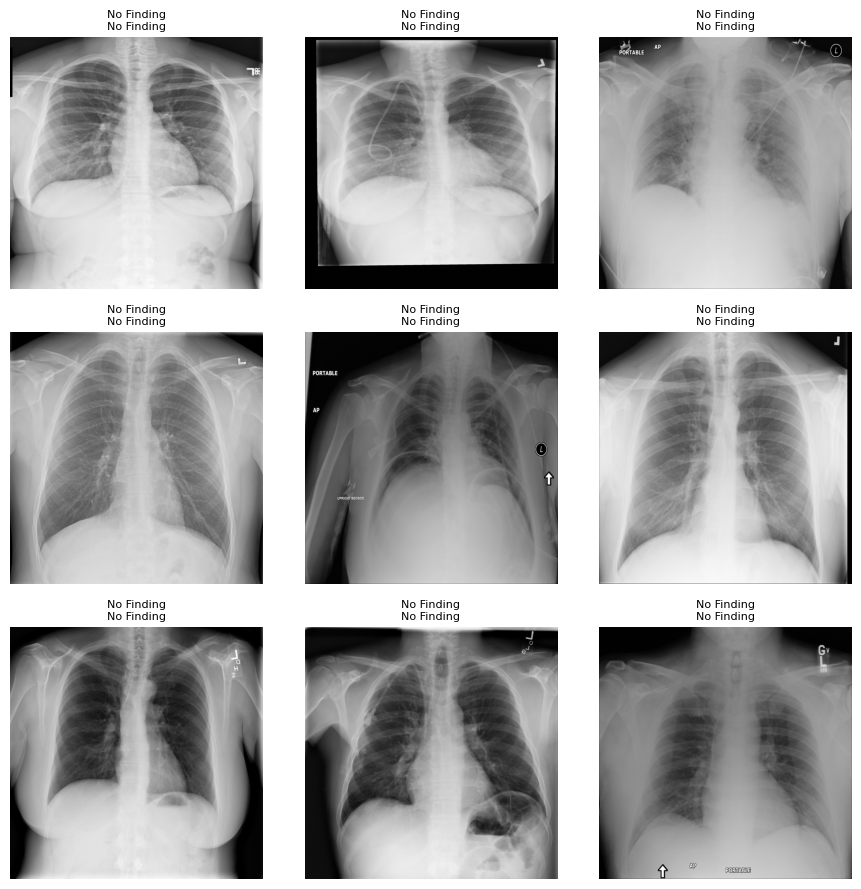

In [73]:
show_examples_for_label(df_clean, 'No Finding', n=9)

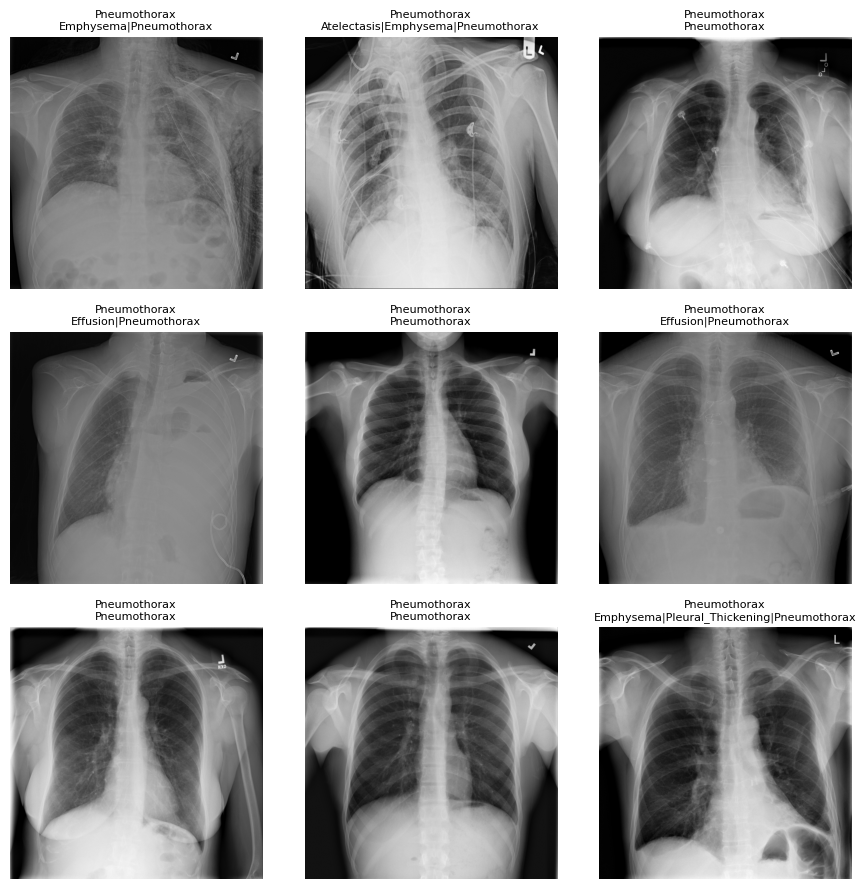

In [74]:
show_examples_for_label(df_clean, 'Pneumothorax', n=9)

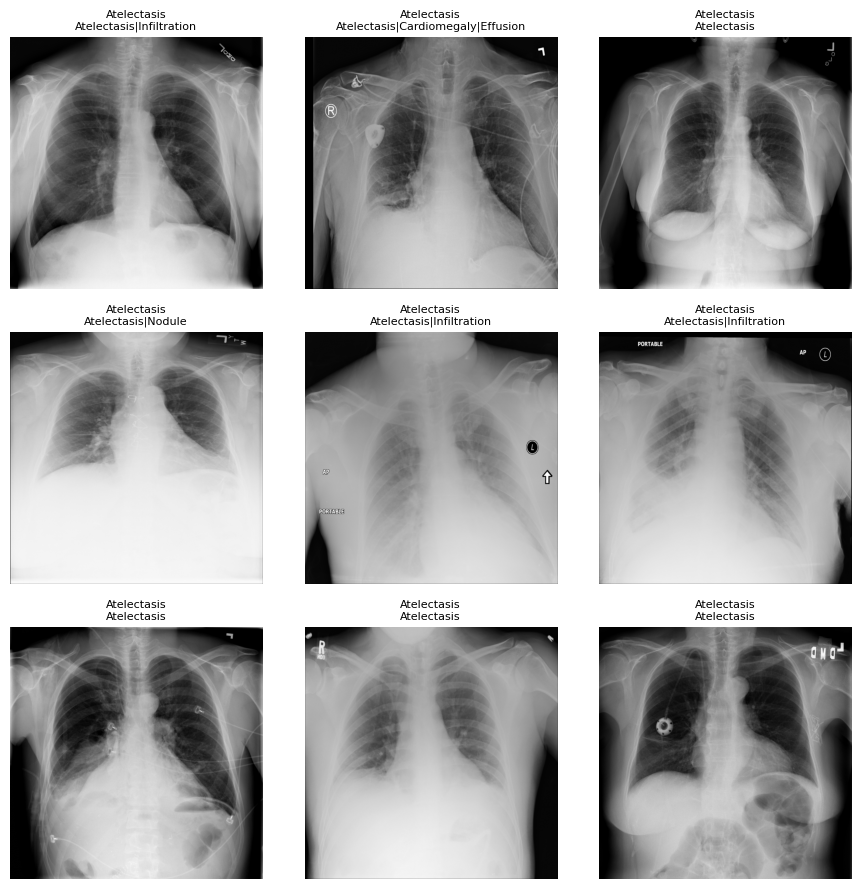

In [75]:
show_examples_for_label(df_clean, 'Atelectasis', n=9)

<Axes: xlabel='num_labels'>

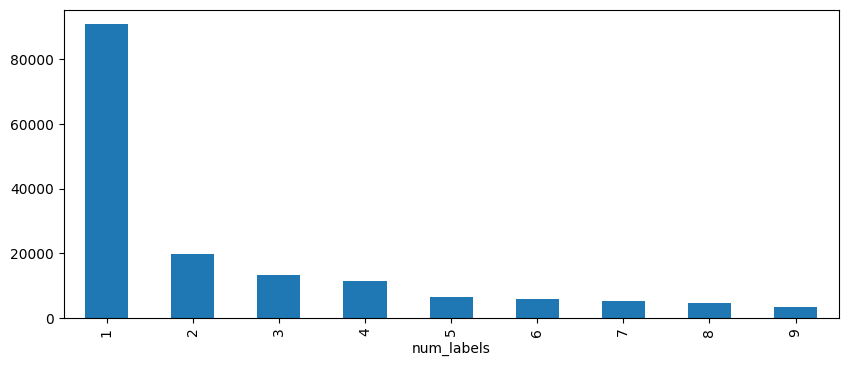

In [76]:
# checking class distributions and label frequencies
class_counts = df_clean[all_labels].sum().sort_values(ascending=False)
class_counts.plot(kind="bar", figsize=(10,4))

df_clean["num_labels"] = df_clean[all_labels].sum(axis=1)
df_clean["num_labels"].value_counts().sort_index().plot(kind="bar")


Most images have only 1 label and there are no images that are unlabeled. This means most images contain single documented pathology. But a substantial number of images have 2-4 pathologies, and some up to 9. Therefore dataset should be treated as a multi-label classificaation. This also means some of the rarer disease combinations will be underrepresented

# Preprocessing

In [77]:
def read_split_file(path):
    '''
    Function to read a split file and return a set of image filenames.
    
    Parameters:
    path: path to split file
    
    Returns:
    set of image filenames
    '''
    
    with open(path, 'r') as f:
        return {line.strip() for line in f.readlines()}
    

train_val_list = read_split_file('train_val_list.txt')
test_list = read_split_file('test_list.txt')

df_model = df_clean.copy()

# everything that is in test_list is test, rest is train_val
df_model["split"] = "train_val"
df_model.loc[df_model["Image Index"].isin(test_list), "split"] = "test"

# keep only rows that  appear in either train_val or test lists
df_model = df_model[df_model["Image Index"].isin(train_val_list | test_list)].reset_index(drop=True)

# multi-hot label columns
label_cols = [
    c for c in df_model.columns 
    if c in ["Atelectasis","Cardiomegaly","Consolidation","Edema","Effusion",
             "Emphysema","Fibrosis","Hernia","Infiltration","Mass",
             "Nodule","Pleural_Thickening","Pneumonia","Pneumothorax",
             "No Finding"]
]

# split train vs val from train_val group (e.g. 80-20 split)
train_val_df = df_model[df_model["split"] == "train_val"].copy()

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,
    random_state=42,
    stratify=train_val_df[label_cols].sum(axis=1)  # keeps label count distribution similar
)

test_df = df_model[df_model["split"] == "test"].copy()


In [78]:
IMG_SIZE = 224

# define transforms for training and validation/test sets
train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

val_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

class NIHChestXrayDataset(Dataset):
    '''
    Custom Dataset for NIH Chest X-ray images and multi-labels.
    Parameters:
    df: dataframe containing image paths and labels
    label_cols: list of label columns
    transform: transform to apply to images
    
    Returns:
    image tensor and multi-label tensor
    '''
    # initialize dataset
    def __init__(self, df, label_cols, transform=None):
        df = df.reset_index(drop=True)
        self.img_paths = df["img_path"].astype(str).tolist()
        self.labels = df[label_cols].to_numpy(dtype=np.float32)
        self.transform = transform

    # return length of dataset
    def __len__(self):
        return len(self.img_paths)

    # get item by index
    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)

        labels = torch.from_numpy(self.labels[idx])  # already float32
        return img, labels

In [79]:
# set batch size and number of workers
BATCH_SIZE = 64
NUM_WORKERS = 0 # can adjust based on CPU

# create datasets for train, val, test sets
train_ds = NIHChestXrayDataset(train_df, label_cols, transform=train_tf)
val_ds   = NIHChestXrayDataset(val_df,   label_cols, transform=val_tf)
test_ds  = NIHChestXrayDataset(test_df,  label_cols, transform=val_tf)

common_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

# only valid when using multiprocessing
#if NUM_WORKERS > 0:
#    common_kwargs.update(dict(
#        persistent_workers=True,
#        prefetch_factor=4,
#    ))

train_loader = DataLoader(
    train_ds,
    shuffle=True,
    **common_kwargs
)

val_loader = DataLoader(
    val_ds,
    shuffle=False,
    **common_kwargs
)

test_loader = DataLoader(
    test_ds,
    shuffle=False,
    **common_kwargs
)


In [80]:
#from torch.utils.data import DataLoader
#
#debug_loader = DataLoader(
#    train_ds,
#    batch_size=32,
#    shuffle=True,
#    num_workers=0,        # IMPORTANT
#    pin_memory=True,
#)


In [81]:
#import time
#t0 = time.perf_counter()
#imgs, labels = next(iter(debug_loader))
#print("ok:", imgs.shape, labels.shape, "time:", time.perf_counter() - t0)

gonna use DenseNet 121, ImageNet pretrained weights. Classifier will be replaced with a linear layer of 15 outputs (may exclude no finding for a future model to see how it will perform)

In [82]:
print("torch:", torch.__version__)
print("torch.version.cuda:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("using device:", device)

num_classes = len(label_cols)

# load pre-trained DenseNet121 model
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
in_features = model.classifier.in_features
model.classifier = nn.Linear(in_features, num_classes)

# move model to device
model = model.to(device)

print("model device:", next(model.parameters()).device)

# define loss function and optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


torch: 2.9.1+cu126
torch.version.cuda: 12.6
cuda available: True
using device: cuda
model device: cuda:0


In [83]:
print("CUDA available:", torch.cuda.is_available())
print("torch.version.cuda:", torch.version.cuda)
print("torch.__version__:", torch.__version__)

CUDA available: True
torch.version.cuda: 12.6
torch.__version__: 2.9.1+cu126


In [84]:
import sys

print("NOTEBOOK python:", sys.executable)
print("NOTEBOOK torch:", torch.__version__)
print("NOTEBOOK torch cuda:", torch.version.cuda)
print("NOTEBOOK cuda available:", torch.cuda.is_available())

NOTEBOOK python: c:\Users\Sahib Mukker\AppData\Local\Programs\Python\Python313\python.exe
NOTEBOOK torch: 2.9.1+cu126
NOTEBOOK torch cuda: 12.6
NOTEBOOK cuda available: True


In [85]:
#import torch
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())
print(torch.__file__)

2.9.1+cu126
12.6
True
c:\Users\Sahib Mukker\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\__init__.py


In [86]:
#import time, torch
#
#def speed_probe(loader, model, criterion, optimizer, device, steps=20):
#    model.train()
#    it = iter(loader)
#
#    # warmup (important)
#    imgs, labels = next(it)
#    imgs = imgs.to(device, non_blocking=True)
#    labels = labels.to(device, non_blocking=True)
#    out = model(imgs)
#    loss = criterion(out, labels)
#    loss.backward()
#    optimizer.zero_grad(set_to_none=True)
#    if device.type == "cuda":
#        torch.cuda.synchronize()
#
#    for i in range(steps):
#        t0 = time.perf_counter()
#        imgs, labels = next(it)                 # load + decode + transforms
#        t1 = time.perf_counter()
#
#        imgs = imgs.to(device, non_blocking=True)
#        labels = labels.to(device, non_blocking=True)
#
#        t2 = time.perf_counter()
#        out = model(imgs)
#        loss = criterion(out, labels)
#        loss.backward()
#        optimizer.zero_grad(set_to_none=True)
#        if device.type == "cuda":
#            torch.cuda.synchronize()
#          t3 = time.perf_counter()
#
#      print(f"{i:02d} data={t1-t0:.3f}s  step={t3-t2:.3f}s  total={(t3-t0):.3f}s")
#
#speed_probe(train_loader, model, criterion, optimizer, device)

In [87]:
#import time
#
#t0 = time.perf_counter()
#batch = next(iter(train_loader))
#t1 = time.perf_counter()
#
#imgs, labels = batch
#print("loaded batch:", imgs.shape, labels.shape, "in", round(t1 - t0, 3), "sec")


In [88]:
#import time
#
#for i in range(5000):
#    t0 = time.perf_counter()
#    x, y = train_ds[i]
#    dt = time.perf_counter() - t0
#    if dt > 2.0:  # threshold, tweak if needed
#        print("slow sample at idx", i, "time", round(dt, 3), "sec")
#        print("path:", train_ds.img_paths[i] if hasattr(train_ds, "img_paths") else "check your dataset class")
#        break
#else:
#    print("no slow samples in first 5000")


In [89]:
#import time, torch
#
#model.train()
#it = iter(train_loader)
#
#for i in range(20):
#    t0 = time.perf_counter()
#    imgs, labels = next(it)                    # data loading + transforms
#    t1 = time.perf_counter()
#
#    imgs = imgs.to(device, non_blocking=True)
#    labels = labels.to(device, non_blocking=True)
#
#    t2 = time.perf_counter()
#    with torch.autocast(device_type="cuda", enabled=(device.type=="cuda")):
#        out = model(imgs)
#        loss = criterion(out, labels)
#    loss.backward()
#    optimizer.zero_grad(set_to_none=True)
#    if device.type == "cuda":
#        torch.cuda.synchronize()
#    t3 = time.perf_counter()
#
#    print(f"{i:02d} data={t1-t0:.3f}s  compute={t3-t2:.3f}s  total={t3-t0:.3f}s")


In [90]:
#df_clean.to_csv("df_clean.csv", index=False)